In [2]:
# 1초에 16,000개의 샘플을 갖는 waveform 생성
import torch

sample_rate = 16_000
duration = 1  # 초
num_samples = sample_rate * duration

waveform = torch.zeros(1, num_samples)
print(waveform.shape)

torch.Size([1, 16000])


In [3]:
# 2초에 32,000개의 샘플을 갖는 waveform 생성

duration = 2  # 초
num_samples = sample_rate * duration
waveform = torch.zeros(1, num_samples)
print(waveform.shape)

torch.Size([1, 32000])


In [4]:

import math
from IPython.display import Audio

frequency = 440  # 소리가 1초에 440번 진동해요

time = torch.arange(num_samples) / sample_rate
wave = 0.2 * torch.sin(2 * math.pi * frequency * time)
waveform = wave.unsqueeze(0)

print(waveform.shape)
print(waveform[0, :5])

Audio(waveform[0].numpy(), rate=sample_rate, normalize=False)

torch.Size([1, 32000])
tensor([0.0000, 0.0344, 0.0677, 0.0991, 0.1275])


In [5]:

import math
from IPython.display import Audio

frequency = 880  # 소리가 1초에 880번 진동해요

time = torch.arange(num_samples) / sample_rate
wave = 0.2 * torch.sin(2 * math.pi * frequency * time)
waveform = wave.unsqueeze(0)

print(waveform.shape)
print(waveform[0, :5])

Audio(waveform[0].numpy(), rate=sample_rate, normalize=False)

torch.Size([1, 32000])
tensor([0.0000, 0.0677, 0.1275, 0.1721, 0.1965])


In [6]:
import math
from IPython.display import Audio

frequency = 880  # 1초에 880번 진동

time = torch.arange(num_samples) / sample_rate
wave = 0.2 * torch.sin(2 * math.pi * frequency * time)
waveform = wave.unsqueeze(0)

print("파형 shape:", waveform.shape)
print("샘플링 주파수:", sample_rate, "Hz")
print("재생 길이:", waveform.shape[-1] / sample_rate, "초")

Audio(waveform[0].numpy(), rate=sample_rate, normalize=False)

파형 shape: torch.Size([1, 32000])
샘플링 주파수: 16000 Hz
재생 길이: 2.0 초


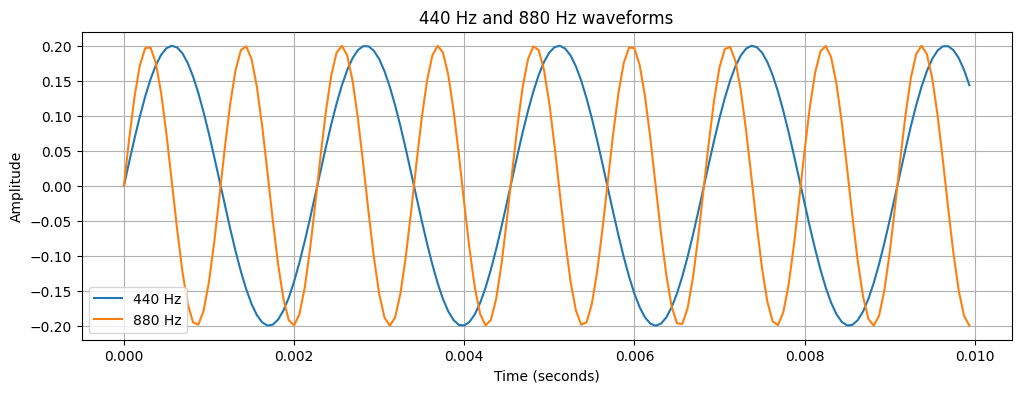

샘플 개수: 160


In [7]:
import math
import torch
import matplotlib.pyplot as plt

sample_rate = 16_000
duration = 0.01  # 0.01초, 즉 10밀리초

num_samples = int(sample_rate * duration)
time = torch.arange(num_samples) / sample_rate

wave_440 = 0.2 * torch.sin(2 * math.pi * 440 * time)
wave_880 = 0.2 * torch.sin(2 * math.pi * 880 * time)

plt.figure(figsize=(12, 4))
plt.plot(time, wave_440, label="440 Hz")
plt.plot(time, wave_880, label="880 Hz")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("440 Hz and 880 Hz waveforms")
plt.legend()
plt.grid()
plt.show()

print("샘플 개수:", num_samples)

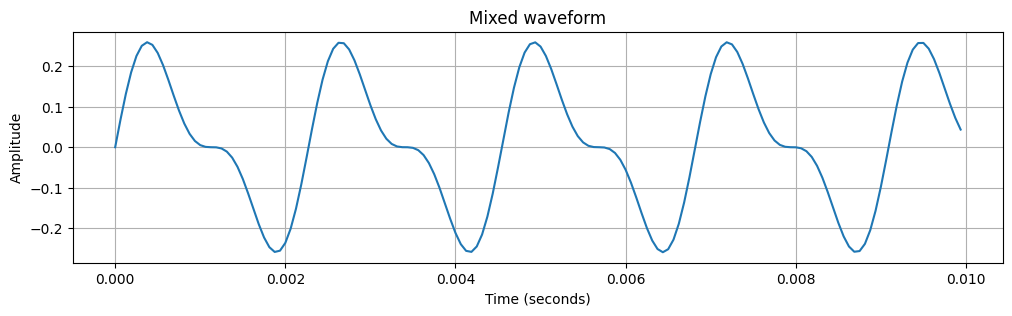

In [8]:
import math
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio

sample_rate = 16_000
duration = 1  # 초
num_samples = sample_rate * duration

time = torch.arange(num_samples) / sample_rate

# 두 소리를 각각 만들고 더하기
wave_440 = 0.2 * torch.sin(2 * math.pi * 440 * time)
wave_880 = 0.1 * torch.sin(2 * math.pi * 880 * time)
mixed_wave = wave_440 + wave_880

# 처음 0.01초만 그래프로 보기
samples_to_show = int(0.01 * sample_rate)

plt.figure(figsize=(12, 3))
plt.plot(time[:samples_to_show], mixed_wave[:samples_to_show])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Mixed waveform")
plt.grid()
plt.show()

Audio(mixed_wave.numpy(), rate=sample_rate, normalize=False)

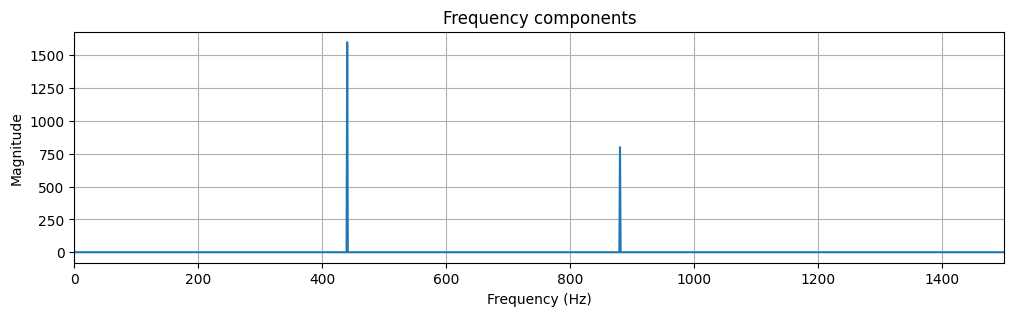

In [9]:
# 파형을 주파수별 성분으로 변환
spectrum = torch.fft.rfft(mixed_wave)

# 각 성분의 크기와 그에 해당하는 주파수
magnitude = torch.abs(spectrum)
frequencies = torch.fft.rfftfreq(num_samples, d=1 / sample_rate)

plt.figure(figsize=(12, 3))
plt.plot(frequencies, magnitude)
plt.xlim(0, 1500)  # 0~1500Hz 구간만 확대
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency components")
plt.grid()
plt.show()

In [10]:
import math
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio

sample_rate = 16_000
half_duration = 0.5

num_samples = int(sample_rate * half_duration)
time = torch.arange(num_samples) / sample_rate

# 앞부분은 440Hz, 뒷부분은 880Hz
wave_440 = 0.2 * torch.sin(2 * math.pi * 440 * time)
wave_880 = 0.2 * torch.sin(2 * math.pi * 880 * time)

# 두 파형을 시간 순서대로 이어 붙이기
waveform = torch.cat([wave_440, wave_880])                  # 앞부분과 뒷부분을 이어 붙이기

print("파형 shape:", waveform.shape)                        # shape = 모든 샘플 수
print("전체 길이:", waveform.shape[0] / sample_rate, "초")  #sample_rate = 16,000Hz이므로, 전체 길이는 샘플 수 / 16,000초   

Audio(waveform.numpy(), rate=sample_rate, normalize=False)

파형 shape: torch.Size([16000])
전체 길이: 1.0 초


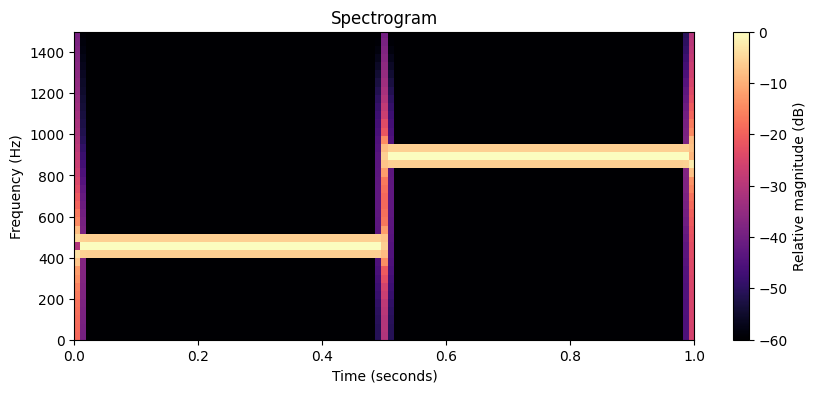

스펙트로그램 shape: torch.Size([201, 101])


In [ ]:
# 한 번에 살펴볼 구간은 400개 샘플, 다음 구간까지는 160개 샘플 이동
window_size = 400
hop_size = 160

window = torch.hann_window(window_size)

# 짧은 구간마다 주파수 성분을 계산
spectrum = torch.stft(          
    waveform,
    n_fft=window_size,
    hop_length=hop_size,
    window=window,
    return_complex=True,
)

magnitude = torch.abs(spectrum)

# 가장 큰 값을 기준으로 상대적인 크기를 dB로 표현
magnitude_db = 20 * torch.log10(magnitude.clamp_min(1e-10))
magnitude_db = magnitude_db - magnitude_db.max()

plt.figure(figsize=(10, 4))
plt.imshow(
    magnitude_db.numpy(),
    origin="lower",
    aspect="auto",
    extent=[0, len(waveform) / sample_rate, 0, sample_rate / 2],
    cmap="magma",
    vmin=-60,
    vmax=0,
)

plt.ylim(0, 1500)
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram")
plt.colorbar(label="Relative magnitude (dB)")
plt.show()

print("스펙트로그램 shape:", magnitude.shape)

# 0.5초 에 아래에서 위로 올라갔기 때문에 낮은 음이 높은 음으로 바뀌었다

In [12]:
print("스펙트로그램 shape:", magnitude.shape)

num_frequencies = magnitude.shape[0]
num_frames = magnitude.shape[1]

print("주파수 칸 수:", num_frequencies)
print("시간 구간 수:", num_frames)

스펙트로그램 shape: torch.Size([201, 101])
주파수 칸 수: 201
시간 구간 수: 101


In [13]:
# [주파수, 시간] → [시간, 주파수]
features = magnitude.transpose(0, 1)

print("변환 전:", magnitude.shape)
print("변환 후:", features.shape)
print("첫 번째 프레임:", features[0].shape)

변환 전: torch.Size([201, 101])
변환 후: torch.Size([101, 201])
첫 번째 프레임: torch.Size([201])


In [14]:
import torch.nn as nn

# 배치 축 추가: [시간, 특징] → [배치, 시간, 특징]
batch = features.unsqueeze(0)

# 각 프레임의 특징 201개를 64개로 변환
projection = nn.Linear(201, 64)
output = projection(batch)

print("입력 shape:", batch.shape)
print("출력 shape:", output.shape)

입력 shape: torch.Size([1, 101, 201])
출력 shape: torch.Size([1, 101, 64])


In [15]:
import torch.nn as nn

# 프레임별 특징 64개를 토큰 점수 3개로 변환
classifier = nn.Linear(64, 3)
scores = classifier(output)

print("Encoder 출력:", output.shape)
print("토큰 점수:", scores.shape)
print("첫 번째 프레임의 점수:", scores[0, 0])

Encoder 출력: torch.Size([1, 101, 64])
토큰 점수: torch.Size([1, 101, 3])
첫 번째 프레임의 점수: tensor([-1.0191,  0.3044, -0.5484], grad_fn=<SelectBackward0>)


In [16]:
tokens = ["∅", "가", "나"]
blank_id = 0

# 각 프레임에서 선택됐다고 가정한 토큰 번호
frame_ids = [1, 1, 2, 2, 0]

decoded = []
previous_id = None

for token_id in frame_ids:
    # 바로 이전 프레임과 다르고 blank가 아니면 결과에 추가
    if token_id != previous_id and token_id != blank_id:
        decoded.append(tokens[token_id])

    previous_id = token_id

print("프레임별 토큰:", [tokens[i] for i in frame_ids])
print("인식 결과:", "".join(decoded))

프레임별 토큰: ['가', '가', '나', '나', '∅']
인식 결과: 가나


In [17]:
import math
import torch

sample_rate = 16_000
duration = 1.0
frequency = 440

# 1초짜리 파형 만들기
num_samples = int(sample_rate * duration)
time = torch.arange(num_samples) / sample_rate
waveform = 0.2 * torch.sin(2 * math.pi * frequency * time)

# 0.1초에 해당하는 샘플 수
chunk_duration = 0.2
chunk_size = int(sample_rate * chunk_duration)

print("전체 파형 shape:", waveform.shape)
print("조각당 샘플 수:", chunk_size)

# 파형을 처음부터 0.1초씩 나누기
for start in range(0, num_samples, chunk_size):
    end = min(start + chunk_size, num_samples)
    chunk = waveform[start:end]

    print(
        f"{start / sample_rate:.1f}초 ~ {end / sample_rate:.1f}초",
        f"shape: {chunk.shape}"
    )

전체 파형 shape: torch.Size([16000])
조각당 샘플 수: 3200
0.0초 ~ 0.2초 shape: torch.Size([3200])
0.2초 ~ 0.4초 shape: torch.Size([3200])
0.4초 ~ 0.6초 shape: torch.Size([3200])
0.6초 ~ 0.8초 shape: torch.Size([3200])
0.8초 ~ 1.0초 shape: torch.Size([3200])


In [18]:
first_chunk = waveform[:chunk_size]  # 처음 0.2초
window_size = 400                   # 25ms를 분석
hop_size = 160                      # 시작점을 10ms씩 이동

# 조각 안에 400개 샘플이 온전히 들어가는 프레임만 만들기
starts = range(0, len(first_chunk) - window_size + 1, hop_size)

print("완성된 프레임 수:", len(starts))
print("첫 프레임:", starts[0], "부터", starts[0] + window_size, "직전까지")
print("끝 프레임:", starts[-1], "부터", starts[-1] + window_size, "직전까지")

완성된 프레임 수: 18
첫 프레임: 0 부터 400 직전까지
끝 프레임: 2720 부터 3120 직전까지


In [19]:
first_chunk = waveform[:int(0.2 * sample_rate)]  # 처음 3,200개 샘플
window_size = 400
hop_size = 160

frames = []
for start in range(0, len(first_chunk) - window_size + 1, hop_size):
    frame = first_chunk[start : start + window_size]
    frames.append(frame)

frames = torch.stack(frames)  # 프레임 하나를 한 행으로 쌓기

print("첫 조각:", first_chunk.shape)
print("꺼낸 프레임:", frames.shape)

첫 조각: torch.Size([3200])
꺼낸 프레임: torch.Size([18, 400])


In [20]:
# 첫 조각은 0~200ms, 두 번째 조각은 200~400ms
second_chunk = waveform[3200:6400]

# 18개 프레임을 처리한 뒤, 다음 프레임이 시작할 위치
next_start = len(frames) * hop_size       # 18 × 160 = 2880
saved = first_chunk[next_start:]          # 180~200ms
needed = window_size - len(saved)         # 400 - 320 = 80

# 두 번째 조각에서 부족한 만큼 가져와 이어 붙이기
next_frame = torch.cat([saved, second_chunk[:needed]])

print("첫 조각에서 보관한 샘플:", len(saved))
print("두 번째 조각에서 가져온 샘플:", needed)
print("완성된 프레임:", next_frame.shape)
print("원본의 같은 구간과 일치:", torch.equal(next_frame, waveform[2880:3280]))

첫 조각에서 보관한 샘플: 320
두 번째 조각에서 가져온 샘플: 80
완성된 프레임: torch.Size([400])
원본의 같은 구간과 일치: True


In [21]:
chunk_size = 3200   # 한 번에 들어오는 0.2초
window_size = 400   # 한 프레임은 25ms
hop_size = 160      # 다음 프레임은 10ms 뒤에서 시작

buffer = waveform[:0]  # 처음에는 비어 있는 텐서
all_frames = []

for i, chunk in enumerate(waveform.split(chunk_size), start=1):
    buffer = torch.cat([buffer, chunk])
    count = 0

    while len(buffer) >= window_size:
        all_frames.append(buffer[:window_size])
        buffer = buffer[hop_size:]
        count += 1

    print(f"조각 {i}: 새 프레임 {count}개, 보관한 샘플 {len(buffer)}개")

all_frames = torch.stack(all_frames)
print("전체 프레임:", all_frames.shape)

조각 1: 새 프레임 18개, 보관한 샘플 320개
조각 2: 새 프레임 20개, 보관한 샘플 320개
조각 3: 새 프레임 20개, 보관한 샘플 320개
조각 4: 새 프레임 20개, 보관한 샘플 320개
조각 5: 새 프레임 20개, 보관한 샘플 320개
전체 프레임: torch.Size([98, 400])


In [22]:
len(buffer)

320

In [23]:
frame = all_frames[0]                     # 첫 25ms의 파형 값 400개
window = torch.hann_window(len(frame))    # 프레임 양 끝을 부드럽게 줄이는 창
strength = torch.fft.rfft(frame * window).abs()

frequencies = torch.fft.rfftfreq(len(frame), d=1 / sample_rate)
peak_index = strength.argmax()            # 가장 강한 주파수 칸의 번호

print("가장 강한 칸:", peak_index.item())
print("그 칸의 주파수:", frequencies[peak_index].item(), "Hz")

가장 강한 칸: 11
그 칸의 주파수: 440.0 Hz


In [24]:
frame_size = all_frames.shape[1]  # 프레임 하나에 샘플 400개
window = torch.hann_window(frame_size)

# 각 프레임에서 주파수별 세기 계산
strengths = torch.fft.rfft(all_frames * window, dim=1).abs()
frequencies = torch.fft.rfftfreq(frame_size, d=1 / sample_rate)

# 각 프레임에서 가장 강한 칸을 찾고, 해당 주파수를 읽기
peak_bins = strengths.argmax(dim=1)
peak_hz = frequencies[peak_bins]

print("주파수 분석 결과:", strengths.shape)
print("처음 5개 프레임의 주파수:", peak_hz[:5].tolist())
print("440Hz가 가장 강한 프레임:", (peak_hz == 440).sum().item(), "/", len(peak_hz))

주파수 분석 결과: torch.Size([98, 201])
처음 5개 프레임의 주파수: [440.0, 440.0, 440.0, 440.0, 440.0]
440Hz가 가장 강한 프레임: 98 / 98
